# 实验 9　关键词提取与章节相似度

## 任务要求

1. 以章节为基本文档，构建 TF-IDF 表示。
2. 为若干指定章节提取关键词，并解释这些词为什么能代表该章。
3. 计算章节之间的相似度，找出最相似的一对或几对章节。
4. 可选：进行简单聚类，并尝试给不同簇起一个描述性名称。

## 方法说明

- 先分词并过滤停用词、单字、纯数字，再用 TF-IDF 向量化（`max_features=1000, min_df=2, max_df=0.8`）。
- 用余弦相似度度量章节两两相似性，并给出 Top 相似章节对。

In [1]:
# 让 notebook 在 notebooks/ 或仓库根目录下都能找到 src/ 包
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "sanguo_nlp").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from sanguo_nlp.paths import FIGURES_DIR, TABLES_DIR, ensure_output_dirs

ensure_output_dirs()
print("已定位仓库根目录:", ROOT.name)

已定位仓库根目录: three-kingdoms-nlp-lab


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

from sanguo_nlp.corpus import load_chapters
from sanguo_nlp.lexicons import load_stopwords
from sanguo_nlp.plotting import use_chinese_font
from sanguo_nlp.similarity import build_tfidf, keywords_table, similarity_pairs, top_keywords
from sanguo_nlp.text import cut, filter_words

use_chinese_font()

chapters = load_chapters()
stopwords = load_stopwords()
chapters["分词"] = chapters["正文"].apply(
    lambda text: " ".join(filter_words(cut(text), stopwords, min_len=2))
)
print("分词示例:", chapters.loc[0, "分词"][:120])

Building prefix dict from the default dictionary ...


Loading model from cache /var/folders/nx/fv3sdh3x51xb4259mz3dpkwc0000gp/T/jieba.cache


Loading model cost 0.431 seconds.


Prefix dict has been built successfully.


分词示例: 天下 大势 分久必合 合久必分 周末 分争 并入 秦灭 分争 并入 于汉 汉朝 高祖 白蛇 起义 一统天下 光武 中兴 传至 献帝 分为 三国 推其致 始于 二帝 桓帝 禁锢 善类 崇信 宦官 及桓帝 灵帝 即位 大将军 窦武 太傅陈 辅佐


In [3]:
matrix, terms = build_tfidf(chapters["分词"])
print("TF-IDF 矩阵形状:", matrix.shape)

TF-IDF 矩阵形状: (120, 1000)


In [4]:
selected = [1, 37, 95, 120]
for chapter in selected:
    print(f"\n第{chapter}回 关键词（TF-IDF 权重）：")
    for word, weight in top_keywords(matrix, terms, chapter - 1, top_k=10):
        print(f"  {word}: {weight:.4f}")


第1回 关键词（TF-IDF 权重）：
  玄德: 0.4061
  黄巾: 0.2911
  叔父: 0.2652
  张飞: 0.2228
  三人: 0.2111
  玄德曰: 0.2069
  董卓: 0.1936
  青州: 0.1808
  姓名: 0.1738
  身长: 0.1499

第37回 关键词（TF-IDF 权重）：
  卧龙: 0.6856
  玄德曰: 0.4424
  童子: 0.2828
  孔明: 0.1888
  玄德: 0.1498
  新野: 0.1426
  刘备: 0.1226
  徐庶: 0.1213
  张飞: 0.0953
  上马: 0.0899

第95回 关键词（TF-IDF 权重）：
  街亭: 0.5820
  司马懿: 0.3406
  马谡: 0.3118
  魏兵: 0.2227
  王平: 0.2036
  孔明: 0.1664
  蜀兵: 0.1569
  山上: 0.1378
  阳平关: 0.1172
  郭淮: 0.1036

第120回 关键词（TF-IDF 权重）：
  陛下: 0.4015
  贾充: 0.2455
  襄阳: 0.2200
  江南: 0.2109
  都督: 0.1863
  大将军: 0.1715
  江陵: 0.1648
  群臣: 0.1549
  吴兵: 0.1404
  渡江: 0.1380


In [5]:
keyword_df = keywords_table(matrix, terms, chapters["章号"], top_k=10)
keyword_df.to_csv(TABLES_DIR / "chapter_tfidf_keywords.csv", index=False, encoding="utf-8-sig")
print("关键词表行数:", len(keyword_df))
keyword_df.head()

关键词表行数: 1200


,章号,关键词,TF-IDF权重
0,1,玄德,0.406073
1,1,黄巾,0.291135
2,1,叔父,0.265204
3,1,张飞,0.222813
4,1,三人,0.211122


In [6]:
similarity_matrix, pair_df = similarity_pairs(matrix)
pair_df.to_csv(TABLES_DIR / "chapter_similarity.csv", index=False, encoding="utf-8-sig")

print("相似度 Top10 章节对:")
print(pair_df.head(10).to_string(index=False))

相似度 Top10 章节对:
 章号A  章号B      相似度
  40   41 0.893372
  25   27 0.890085
  27   28 0.876967
  89   90 0.843904
  58   59 0.831060
  25   28 0.819699
  81   83 0.781053
  83   84 0.775920
  81   84 0.754811
  27   77 0.753711


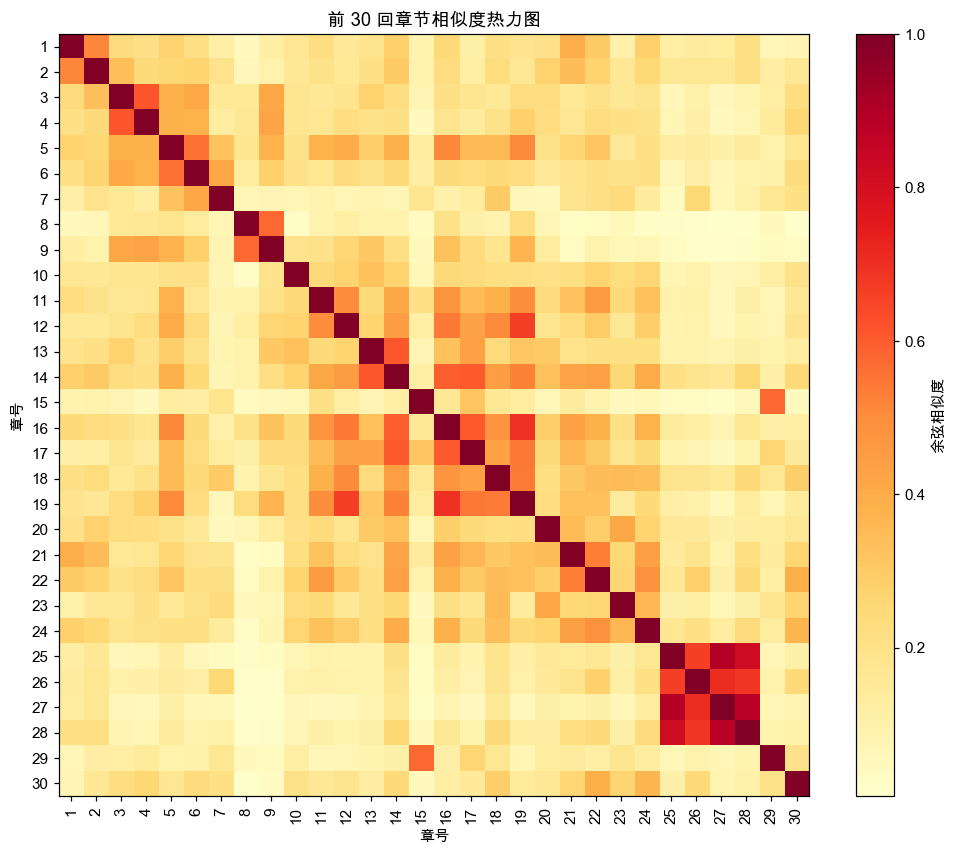

In [7]:
fig, ax = plt.subplots(figsize=(11, 9))
subset = similarity_matrix[:30, :30]
image = ax.imshow(subset, cmap="YlOrRd", aspect="auto")
fig.colorbar(image, ax=ax, label="余弦相似度")
ax.set_xticks(range(30))
ax.set_xticklabels(range(1, 31), rotation=90)
ax.set_yticks(range(30))
ax.set_yticklabels(range(1, 31))
ax.set_xlabel("章号")
ax.set_ylabel("章号")
ax.set_title("前 30 回章节相似度热力图")
fig.savefig(FIGURES_DIR / "similarity_heatmap.png")
plt.show()

In [8]:
n_clusters = 5
labels = KMeans(n_clusters=n_clusters, n_init=10, random_state=42).fit_predict(matrix)
cluster_df = pd.DataFrame({"章号": chapters["章号"], "簇": labels})
cluster_df.to_csv(TABLES_DIR / "chapter_clusters.csv", index=False, encoding="utf-8-sig")

for cluster in range(n_clusters):
    members = cluster_df.loc[cluster_df["簇"] == cluster, "章号"].tolist()
    print(f"簇 {cluster}（{len(members)} 回）：{members}")

簇 0（18 回）：[15, 29, 38, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 54, 55, 56, 57, 66]
簇 1（9 回）：[25, 26, 27, 28, 74, 75, 76, 77, 78]
簇 2（52 回）：[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 17, 18, 19, 20, 21, 22, 23, 24, 30, 31, 32, 33, 34, 35, 36, 37, 39, 40, 41, 42, 53, 58, 59, 60, 61, 62, 63, 64, 65, 67, 68, 69, 70, 71, 72, 73, 79]
簇 3（5 回）：[81, 82, 83, 84, 85]
簇 4（36 回）：[80, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120]


## 讨论与实验记录

- **TF-IDF 相比简单词频的最大改进**：它用逆文档频率压低“曰、之、不”等全书常见词，自动突出每章特有的主题词，更适合关键词提取与相似度计算。
- **章节相似可以来自不同原因**：人物重合（如第 43、44 回都以诸葛亮、周瑜、孙权为核心）、主题相同（赤壁系列、北伐系列），或叙事结构相似（战前议事、宴会、盟誓等场景）。
- 聚类得到的簇往往对应“战争”“权谋”“过渡”等不同功能，命名时需结合具体章节标题判断，不能只凭词向量下结论。

**实验记录**

- 遇到的问题：保存相似度表时 `NameError: name 'pairs' is not defined`，原因是相似度矩阵算完后忘记生成章节对；补上双重循环后解决。
- AI 工具使用记录：AI 助手提供了 `cosine_similarity` 与 KMeans 的示例代码，随后在本地运行并核对输出。